In [1]:
from collections import Counter
from itertools import chain
import matplotlib.pyplot as plt
from nltk.util import ngrams as nltk_ngrams
import numpy as np
import pandas as pd
from pathlib import Path
import re
from scipy.spatial.distance import jensenshannon
import seaborn as sns

In [2]:
# Find all CSV files in the data folder

DATA_PATH = Path("../data/Translated")
csv_files = sorted(DATA_PATH.glob("*.csv"))

print(f"Found {len(csv_files)} files:")
for file in csv_files:
    print(file.name)

Found 17 files:
Speeches_ALDE_Cleaned_Translated.csv
Speeches_CZ_Cleaned_Translated.csv
Speeches_DE_Cleaned_Translated.csv
Speeches_ECB_Cleaned_Translated.csv
Speeches_ECR_Cleaned_Translated.csv
Speeches_EC_Cleaned_Translated.csv
Speeches_EP_Cleaned_Translated.csv
Speeches_EUCouncil_Cleaned_Translated.csv
Speeches_FR_Cleaned_Translated.csv
Speeches_GR_Cleaned_Translated.csv
Speeches_IMF_Cleaned_Translated.csv
Speeches_IT_Cleaned_Translated.csv
Speeches_NL_Cleaned_Translated.csv
Speeches_PL_Cleaned_Translated.csv
Speeches_PO_Cleaned_Translated.csv
Speeches_SP_Cleaned_Translated.csv
Speeches_UK_Cleaned_Translated.csv


In [3]:
# Load all CSV files into DataFrame

ALL_COLUMNS = [
    "title",
    "date",
    "location",
    "speaker",
    "word_count",
    "raw",
    "raw_text",
    "original",
    "lang",
]
USE_COLUMNS = ["title", "date", "location", "speaker", "raw"]


def clean_sentence(text: str) -> str:
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def split_sentences(text: str) -> list[str]:
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [clean_sentence(sentence) for sentence in sentences if sentence.strip()]


def load_speech_csv(path: Path) -> pd.DataFrame:
    nation = path.stem.split("_")[1]
    df = pd.read_csv(path, header=None, names=ALL_COLUMNS, usecols=USE_COLUMNS)
    df["nation"] = nation
    df["sentences"] = df["raw"].apply(split_sentences)
    return df


corpus = pd.concat([load_speech_csv(file) for file in csv_files], ignore_index=True)

expected = {file.stem.split("_")[1] for file in csv_files}
loaded = set(corpus["nation"].unique())
missing = expected - loaded
if missing:
    print(f"[WARNING] No speeches loaded for: {missing}")


NATIONS = {"CZ", "DE", "FR", "GR", "IT", "NL", "PL", "PO", "SP", "UK"}
institutional_corpus = corpus[~corpus["nation"].isin(NATIONS)].reset_index(drop=True)
corpus = corpus[corpus["nation"].isin(NATIONS)].reset_index(drop=True)

print(f"Nation corpus: {len(corpus)} speeches")
print(f"Institutional corpus: {len(institutional_corpus)} speeches")

[WARNING] No speeches loaded for: {'UK', 'IMF'}
Nation corpus: 4852 speeches
Institutional corpus: 1254 speeches


In [4]:
corpus.groupby("nation").size().sort_values(ascending=False).rename("speech_count")

nation
FR    1451
SP     996
IT     804
DE     580
GR     390
NL     260
CZ     234
PO     133
PL       4
Name: speech_count, dtype: int64

In [5]:
# Exporting corpus for SRILM

output_directory = Path("../output/countries")
output_directory.mkdir(parents=True, exist_ok=True)

for nation, group in corpus.groupby("nation"):
    output_file = output_directory / f"{nation}.txt"

    with open(output_file, "w", encoding="utf-8") as output:
        for sentence_list in group["sentences"]:
            for sentence in sentence_list:
                output.write(sentence + "\n")

In [6]:
def tokenize_sentences(sentences: list[str]) -> list[list[str]]:
    return [sentence.split() for sentence in sentences if sentence.strip()]


corpus["tokens"] = corpus["sentences"].apply(tokenize_sentences)
institutional_corpus["tokens"] = institutional_corpus["sentences"].apply(
    tokenize_sentences
)

In [7]:
def build_ngram_counts(token_lists: list[list[str]], n: int) -> Counter:
    """Count n-grams from a list of tokenized sentences"""
    counter = Counter()
    for tokens in token_lists:
        padded = ["<s>"] * (n - 1) + tokens + ["</s>"]
        counter.update(nltk_ngrams(padded, n))
    return counter

In [8]:
def build_universal_ngram_vocab(corpus: pd.DataFrame, n: int, cutoff: int = 2) -> list:
    """Build the universal n-gram vocabulary across all nations"""
    total: Counter = Counter()
    for token_lists in corpus["tokens"]:
        total.update(build_ngram_counts(token_lists, n))
    return [ngram for ngram, count in total.items() if count >= cutoff]

In [9]:
def get_ngram_probability_vector(
    nation_counts: Counter, universal_ngrams: list, ngram_index: dict
) -> np.ndarray:
    """Laplace-smoothed probability vector over the universal n-gram vocabulary"""
    counts = np.ones(len(universal_ngrams), dtype=np.float64)
    for ngram, count in nation_counts.items():
        if ngram in ngram_index:
            counts[ngram_index[ngram]] += count
    return counts / counts.sum()

In [10]:
def compute_jsd_matrix(
    corpus: pd.DataFrame, nations: list[str], n: int
) -> tuple[pd.DataFrame, list, dict, np.ndarray]:
    universal_ngrams = build_universal_ngram_vocab(corpus, n)
    ngram_index = {ngram: i for i, ngram in enumerate(universal_ngrams)}
    print(f"n={n} | vocab size: {len(universal_ngrams):,}")

    probability_matrix = []
    for nation in nations:
        group = corpus[corpus["nation"] == nation]
        token_lists = list(chain.from_iterable(group["tokens"]))
        counts = build_ngram_counts(token_lists, n)
        vector = get_ngram_probability_vector(counts, universal_ngrams, ngram_index)
        probability_matrix.append(vector)

    probability_matrix = np.vstack(probability_matrix)

    number_nations = len(nations)
    jsd = np.zeros((number_nations, number_nations))
    for i in range(number_nations):
        for j in range(i + 1, number_nations):
            score = (
                jensenshannon(probability_matrix[i], probability_matrix[j], base=2) ** 2
            )
            jsd[i, j] = jsd[j, i] = score

    jsd_df = pd.DataFrame(jsd, index=nations, columns=nations)
    return jsd_df, universal_ngrams, ngram_index, probability_matrix

Computing Unigram JSD:
n=1 | vocab size: 36,422
Computing Bigram JSD:
n=2 | vocab size: 492,667
Computing Trigram JSD:
n=3 | vocab size: 1,006,938


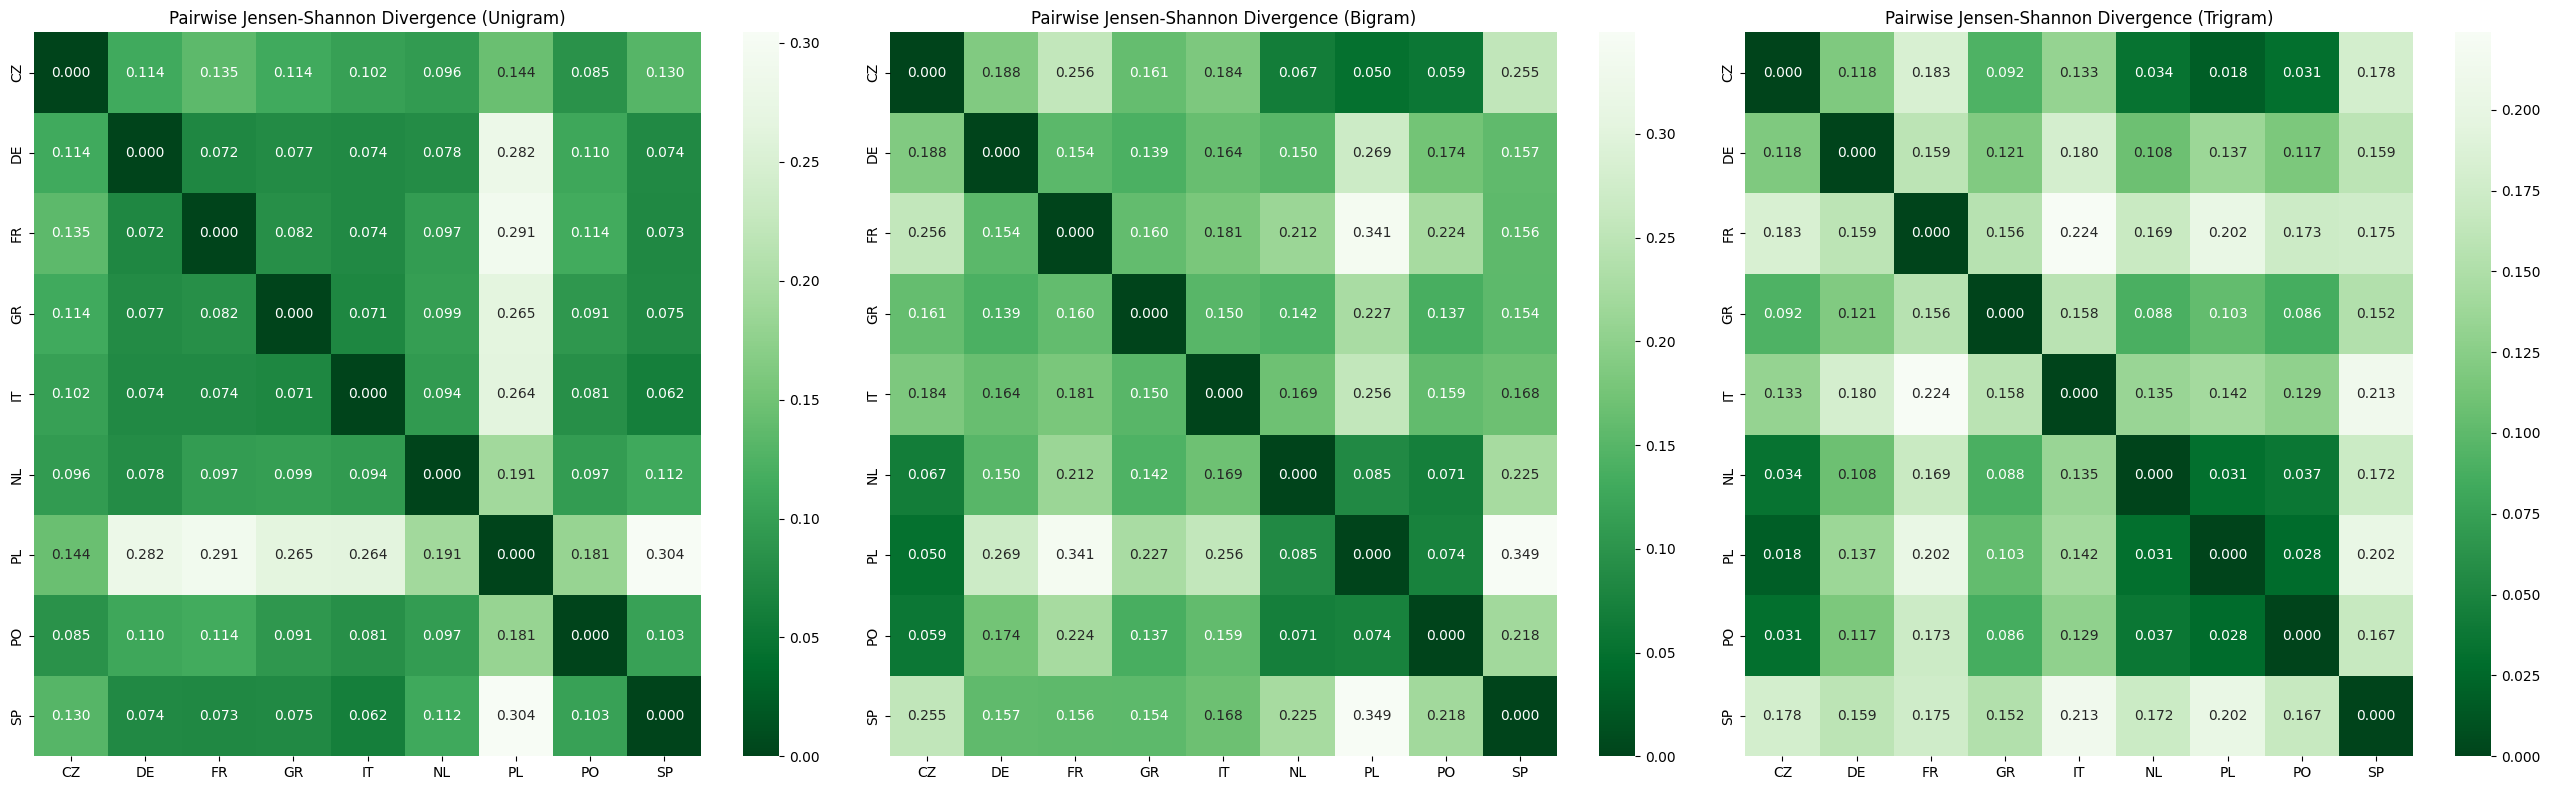

In [11]:
N = 1
saved = {}

nations = sorted(corpus["nation"].unique())
orders = [(1, "Unigram"), (2, "Bigram"), (3, "Trigram")]

figure, axes = plt.subplots(1, 3, figsize=(26, 8))

for axis, (n, label) in zip(axes, orders):
    print(f"Computing {label} JSD:")

    jsd_df, universal_ngrams, ngram_index, probability_matrix = compute_jsd_matrix(
        corpus, nations, n
    )
    if n == N:
        saved = (universal_ngrams, ngram_index, probability_matrix)

    sns.heatmap(jsd_df, annot=True, ax=axis, cmap="Greens_r", fmt=".3f")
    axis.set_title(f"Pairwise Jensen-Shannon Divergence ({label})")

plt.tight_layout()
plt.show()

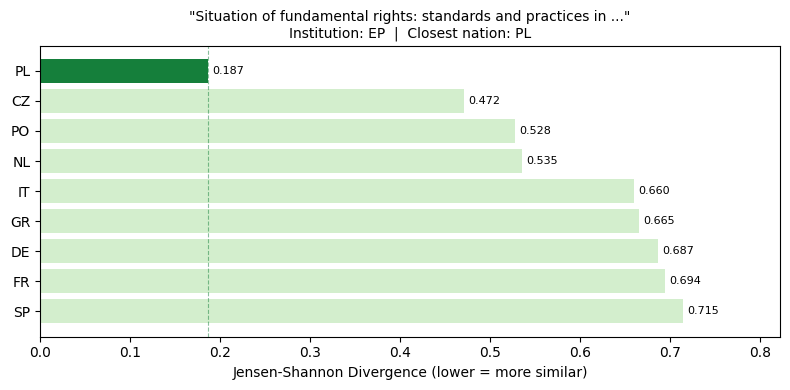

In [12]:
universal_ngrams, ngram_index, probability_matrix = saved
colormap = plt.get_cmap("Greens_r")

sample = institutional_corpus.sample(1).iloc[0]
speech_counts = build_ngram_counts(sample["tokens"], N)
speech_vector = get_ngram_probability_vector(
    speech_counts, universal_ngrams, ngram_index
)
scores = {
    nation: jensenshannon(speech_vector, probability_matrix[i], base=2) ** 2
    for i, nation in enumerate(nations)
}

sorted_scores = dict(sorted(scores.items(), key=lambda item: item[1]))
closest_nation = next(iter(sorted_scores))

figure, axis = plt.subplots(figsize=(8, 4))

colors = [
    colormap(0.2) if nation == closest_nation else colormap(0.8)
    for nation in sorted_scores
]
bars = axis.barh(list(sorted_scores.keys()), list(sorted_scores.values()), color=colors)

axis.set_xlabel("Jensen-Shannon Divergence (lower = more similar)")
axis.set_title(
    f"\"{sample['title'][:60]}...\"\n"
    f"Institution: {sample['nation']}  |  Closest nation: {closest_nation}",
    fontsize=10,
)
axis.axvline(
    x=min(sorted_scores.values()),
    alpha=0.5,
    color=colormap(0.2),
    linestyle="--",
    linewidth=0.8,
)
axis.bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
axis.set_xlim(0, max(sorted_scores.values()) * 1.15)
axis.invert_yaxis()

plt.tight_layout()
plt.show()